In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import sys
import os

sys.path.append(os.path.abspath(".."))

from src.load_master_data import load_master_data

df = load_master_data()

df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 35 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   season                   25939 non-null  int64         
 1   round                    25939 non-null  int64         
 2   driver_id                25939 non-null  category      
 3   driver_name              25939 non-null  category      
 4   constructor_id           25939 non-null  category      
 5   grid                     25939 non-null  int64         
 6   position                 25939 non-null  int64         
 7   points                   25939 non-null  float64       
 8   laps                     25939 non-null  int64         
 9   status                   25939 non-null  category      
 10  time                     8354 non-null   str           
 11  fastest_lap              8785 non-null   str           
 12  fastest_lap_rank         8785 non-null   fl

In [5]:
target = "podium"

df[target].value_counts()

df[target].value_counts(normalize=True)

podium
0    0.865916
1    0.134084
Name: proportion, dtype: float64

In [6]:
features = [
    "grid",
    "qualifying_position",
    "driver_age",
    "pole_position",
    "front_row",
    "constructor_name",
    "driver_nationality",
    "circuit_country"
]

In [7]:
X = df[features]

y = df[target]

In [8]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 25939 entries, 0 to 25938
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   grid                 25939 non-null  int64   
 1   qualifying_position  11029 non-null  float64 
 2   driver_age           25939 non-null  float64 
 3   pole_position        25939 non-null  int64   
 4   front_row            25939 non-null  int64   
 5   constructor_name     25939 non-null  category
 6   driver_nationality   25939 non-null  category
 7   circuit_country      25939 non-null  category
dtypes: category(3), float64(2), int64(3)
memory usage: 1.1 MB


## GRID T TEST

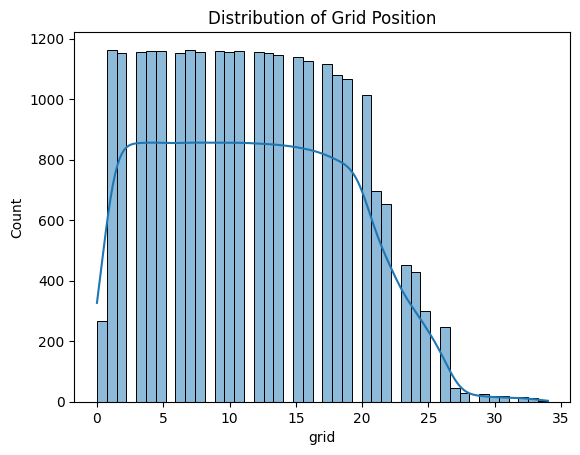

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["grid"], kde=True)

plt.title("Distribution of Grid Position")

plt.show()

In [12]:
from scipy.stats import mannwhitneyu

# Separate groups
podium_group = df[
    df["podium"] == 1
]["grid"]

non_podium_group = df[
    df["podium"] == 0
]["grid"]

# Mann-Whitney U test
u_stat, p_value = mannwhitneyu(
    podium_group,
    non_podium_group,
    alternative="two-sided"
)

print("U-statistic:", u_stat)
print("P-value:", p_value)

U-statistic: 9878160.5
P-value: 0.0


In [13]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'grid' is discriminative.")
else:
    print("Fail to reject H0")
    print("The variable 'grid' is class independent.")

Reject H0
The variable 'grid' is discriminative.


### Hypothesis Test for Grid Position

H0: The variable 'grid' is class independent.

H1: The variable 'grid' is not class independent.

Confidence level = 95%
α = 0.05

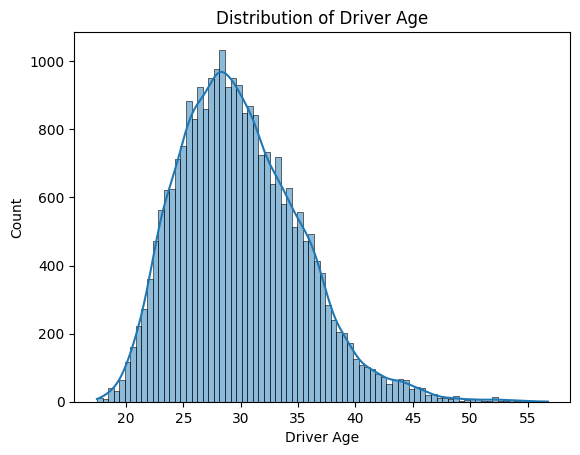

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(
    df["driver_age"],
    kde=True
)

plt.title("Distribution of Driver Age")

plt.xlabel("Driver Age")

plt.ylabel("Count")

plt.show()

In [15]:
from scipy.stats import ttest_ind

# Separate groups
podium_group = df[
    df["podium"] == 1
]["driver_age"]

non_podium_group = df[
    df["podium"] == 0
]["driver_age"]

# T-test
t_stat, p_value = ttest_ind(
    podium_group,
    non_podium_group,
    nan_policy="omit"
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: 7.317266169041524
P-value: 2.6042039713071235e-13


In [16]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The variable 'driver_age' is discriminative.")
else:
    print("Fail to reject H0")
    print("The variable 'driver_age' is class independent.")

Reject H0
The variable 'driver_age' is discriminative.


In [17]:
from scipy.stats import chi2_contingency

# Create contingency table
contingency_table = pd.crosstab(
    df["front_row"],
    df["podium"]
)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 4045.2462825884727
P-value: 0.0


In [18]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Front row starts are associated with podium finishes.")
else:
    print("Fail to reject H0")
    print("Front row starts are independent of podium finishes.")

Reject H0
Front row starts are associated with podium finishes.


In [21]:
from scipy.stats import chi2_contingency

# Contingency table
contingency_table = pd.crosstab(
    df["constructor_name"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print(f"{p_value:.50f}")

Chi-square statistic: 3711.3602882742834
P-value: 0.0
0.00000000000000000000000000000000000000000000000000


In [20]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("Constructor name is associated with podium finishes.")
else:
    print("Fail to reject H0")
    print("Constructor name is independent of podium finishes.")

Reject H0
Constructor name is associated with podium finishes.


In [22]:
# Contingency table
contingency_table = pd.crosstab(
    df["circuit_country"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 9.27955285158374
P-value: 0.999984847062557


In [23]:
# Contingency table
contingency_table = pd.crosstab(
    df["driver_nationality"],
    df["podium"]
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)

Chi-square statistic: 795.4696292875008
P-value: 8.634066317202463e-142
